In [2]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


Morula Boundary 0.0046344004024292985 1.402793892954381
Morula Boundary ±80k 0.09983549316235327 0.8797921210727506
Morula Boundary ±160k 0.00012791846416935367 0.9989668428559046
图片已保存：IVF_2C_EPI_enrich_TADboundary_OR_stars.svg


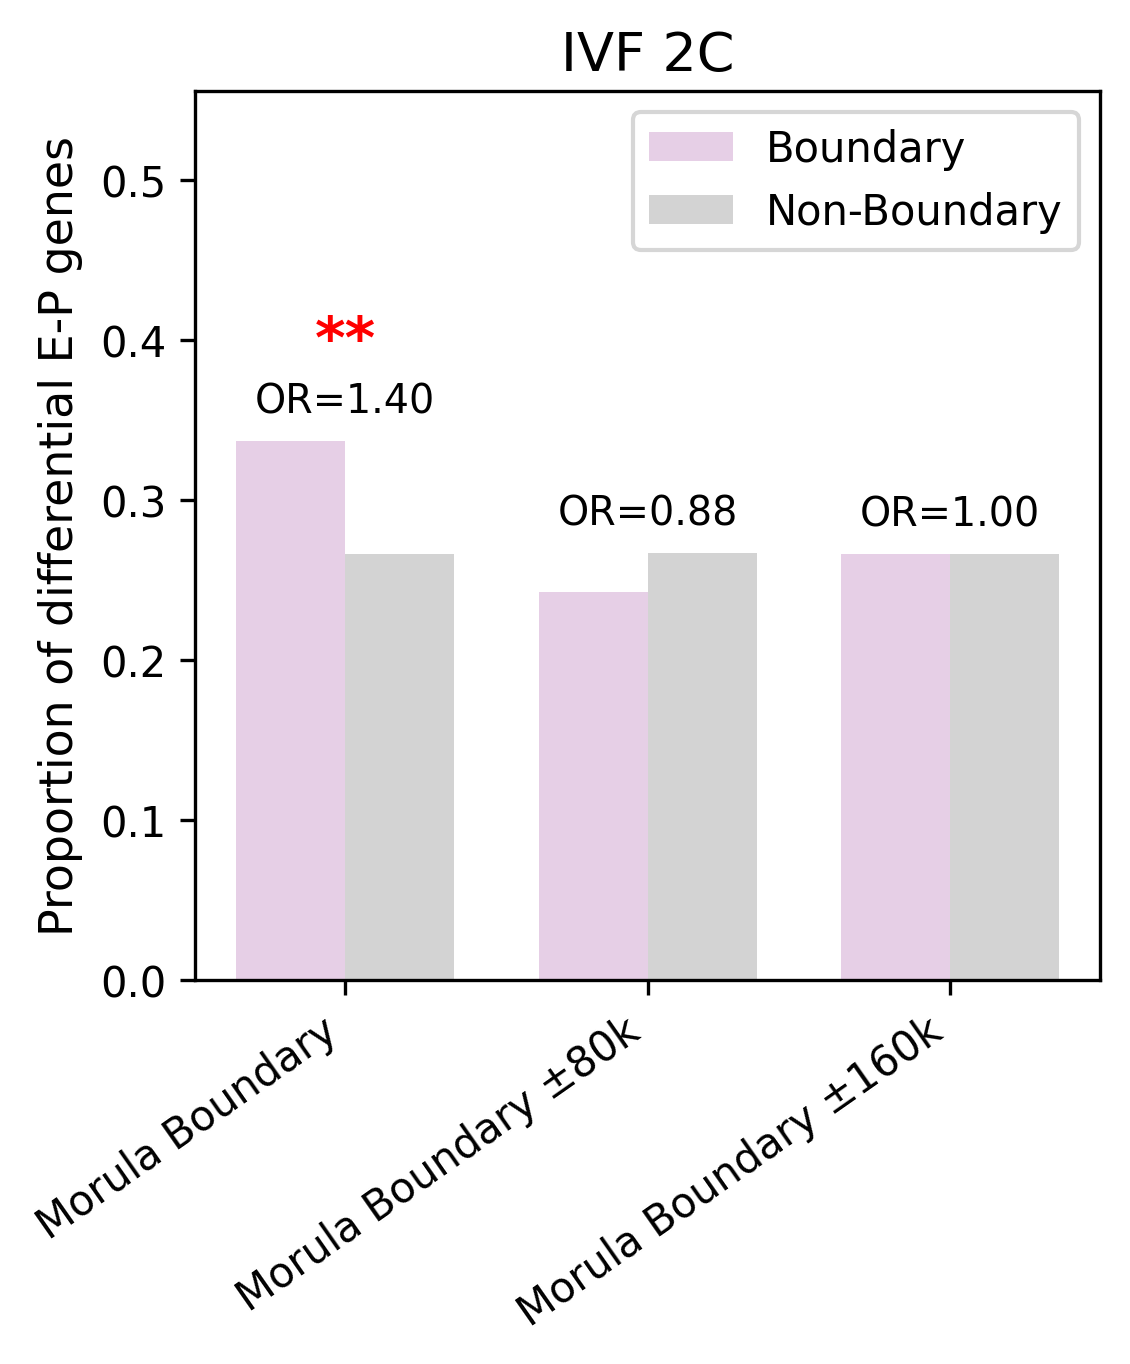

In [3]:
#IVF 2C morula 附近的差异边界
#EPI 在 boundary 富集情况

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")
    
    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d



def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")
    
    conditions = [
        {
            "name": "IVF 2C",
            "diff_file": "IVF_2C_diff_EPgenes.H3K27ac.0.01.txt",
            "regions": [
                ("Morula Boundary", 
                 "dedoc2_IVF_2C_debin_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k", 
                 "dedoc2_IVF_2C_debin_flanking_80k_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k", 
                 "dedoc2_IVF_2C_debin_flanking_160k_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # ── 绘图风格 ───────────────────────────────────────────────────
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes    = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(diff_genes, target_genes, non_genes)
            print(label,p,odds)
            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non    = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width/2, target_props,   width, label="Boundary",     color=colors["Boundary"])
        ax.bar(x + width/2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of differential E-P genes", fontsize=11)
        
        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])
            
            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}', 
                    ha='center', va='bottom', fontsize=9.5)
            
            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"
                
                ax.text(i, max_h + 0.045, stars, 
                        ha='center', va='bottom', fontsize=14, 
                        color='red', fontweight='bold')

        # 图例放到右上角外部
        #ax.legend(frameon=True, fontsize=10, 
        #          loc='upper left', bbox_to_anchor=(1.02, 1.0))
        ax.legend()
    # 整体布局
    fig.suptitle("", 
                 fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)  # 给右侧图例留空间

    # 保存
    output_file = "IVF_2C_EPI_enrich_TADboundary_OR_stars.svg"
    plt.savefig('IVF_2C_EPI_enrich_TADboundary_OR_stars.svg', dpi=300, bbox_inches='tight', transparent=True)
    print(f"图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main() 

Morula Boundary 1.0 0.8042382928275045
Morula Boundary ±80k 0.6383314322820863 0.9268227221807319
Morula Boundary ±160k 0.6432212131959548 0.9944451796363845
图片已保存：IVF_2C_ZGA_enrich_TADboundary_OR_stars.svg


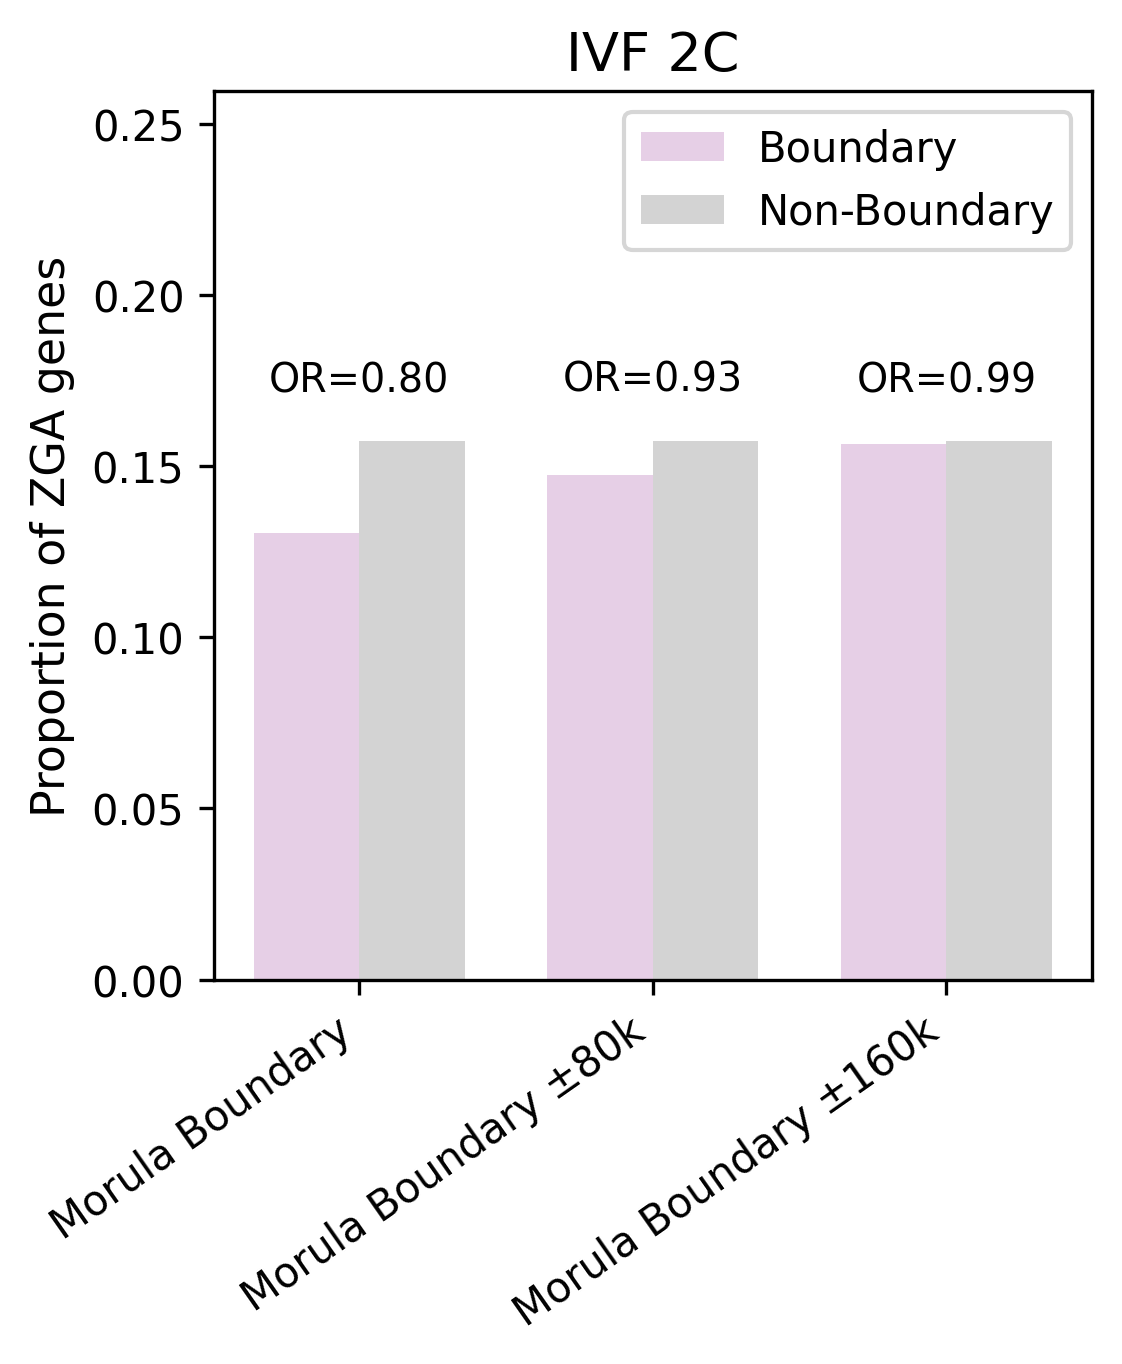

In [4]:
#IVF 2C morula 附近的差异边界
#ZGA 在 boundary 富集情况

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")
    
    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d



def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")
    
    conditions = [
        {
            "name": "IVF 2C",
            "diff_file": "IVF_ZGAid.txt",
            "regions": [
                ("Morula Boundary", 
                 "dedoc2_IVF_2C_debin_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k", 
                 "dedoc2_IVF_2C_debin_flanking_80k_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k", 
                 "dedoc2_IVF_2C_debin_flanking_160k_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # ── 绘图风格 ───────────────────────────────────────────────────
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes    = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(diff_genes, target_genes, non_genes)
            print(label,p,odds)
            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non    = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width/2, target_props,   width, label="Boundary",     color=colors["Boundary"])
        ax.bar(x + width/2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of ZGA genes", fontsize=11)
        
        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])
            
            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}', 
                    ha='center', va='bottom', fontsize=9.5)
            
            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"
                
                ax.text(i, max_h + 0.045, stars, 
                        ha='center', va='bottom', fontsize=14, 
                        color='red', fontweight='bold')

        # 图例放到右上角外部
        #ax.legend(frameon=True, fontsize=10, 
        #          loc='upper left', bbox_to_anchor=(1.02, 1.0))
        ax.legend()
    # 整体布局
    fig.suptitle("", 
                 fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)  # 给右侧图例留空间

    # 保存
    output_file = "IVF_2C_ZGA_enrich_TADboundary_OR_stars.svg"
    plt.savefig('IVF_2C_ZGA_enrich_TADboundary_OR_stars.svg', dpi=300, bbox_inches='tight', transparent=True)
    print(f"图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main() 

Morula Boundary 0.2422381963903693 0.38475540386803186
Morula Boundary ±80k 0.1420921988707467 0.7050066775485977
Morula Boundary ±160k 0.47233948020190464 1.074421810563372
图片已保存：IVF_2C_diff_EPI_ZGA_overlap_enrich_TADboundary_OR_stars.svg


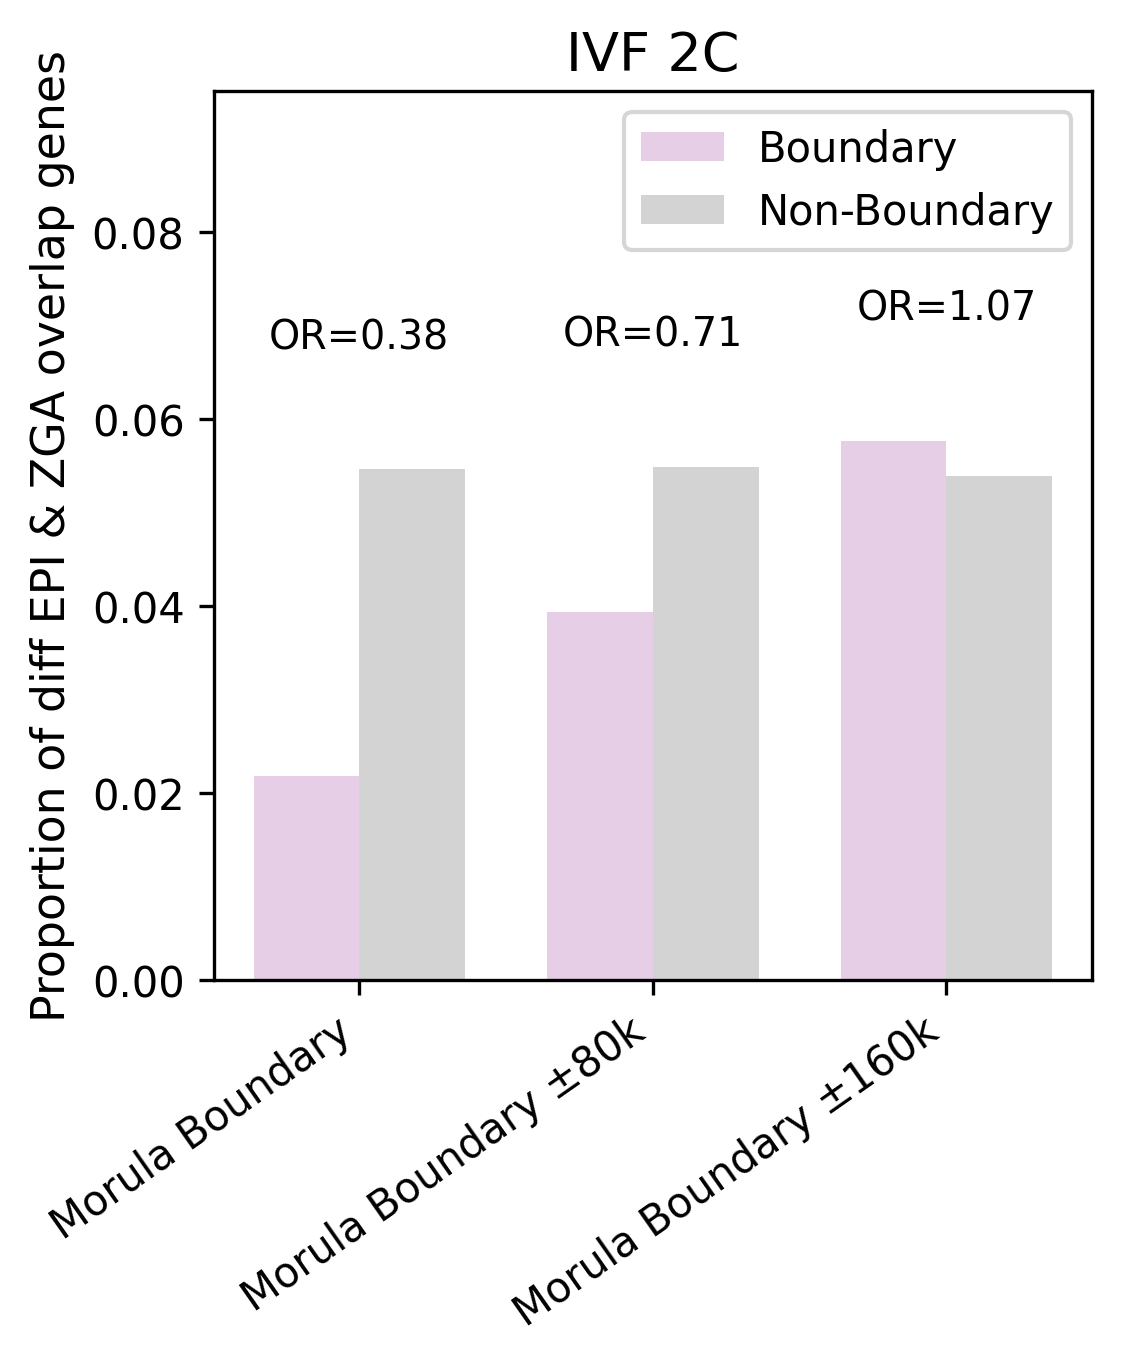

In [9]:
#IVF 2C morula 附近的差异边界
#ZGA 在 boundary 富集情况

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")
    
    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d



def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")
    
    conditions = [
        {
            "name": "IVF 2C",
            "diff_file": "IVF_2C_diff_EPI_ZGA_overlap_id.txt",
            "regions": [
                ("Morula Boundary", 
                 "dedoc2_IVF_2C_debin_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k", 
                 "dedoc2_IVF_2C_debin_flanking_80k_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k", 
                 "dedoc2_IVF_2C_debin_flanking_160k_genes_id.new.txt", 
                 "dedoc2_IVF_2C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # ── 绘图风格 ───────────────────────────────────────────────────
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes    = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(diff_genes, target_genes, non_genes)
            print(label,p,odds)
            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non    = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width/2, target_props,   width, label="Boundary",     color=colors["Boundary"])
        ax.bar(x + width/2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of diff EPI & ZGA overlap genes", fontsize=11)
        
        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])
            
            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}', 
                    ha='center', va='bottom', fontsize=9.5)
            
            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"
                
                ax.text(i, max_h + 0.045, stars, 
                        ha='center', va='bottom', fontsize=14, 
                        color='red', fontweight='bold')

        # 图例放到右上角外部
        #ax.legend(frameon=True, fontsize=10, 
        #          loc='upper left', bbox_to_anchor=(1.02, 1.0))
        ax.legend()
    # 整体布局
    fig.suptitle("", 
                 fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)  # 给右侧图例留空间

    # 保存
    output_file = "IVF_2C_diff_EPI_ZGA_overlap_enrich_TADboundary_OR_stars.svg"
    plt.savefig('IVF_2C_diff_EPI_ZGA_overlap_enrich_TADboundary_OR_stars.svg', dpi=300, bbox_inches='tight', transparent=True)
    print(f"图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main() 


=== IVF 4C ===
Morula Boundary: p = 9.7882e-03, OR = 1.278, 列联表 a=35, b=5994, c=76, d=16635
Morula Boundary ±80k: p = 1.0865e-05, OR = 1.015, 列联表 a=400, b=5629, c=1093, d=15618
Morula Boundary ±160k: p = 1.4792e-03, OR = 1.029, 列联表 a=1296, b=4733, c=3512, d=13199

图片已保存：IVF_4C_EPI_enrich_TADboundary_OR_stars.svg


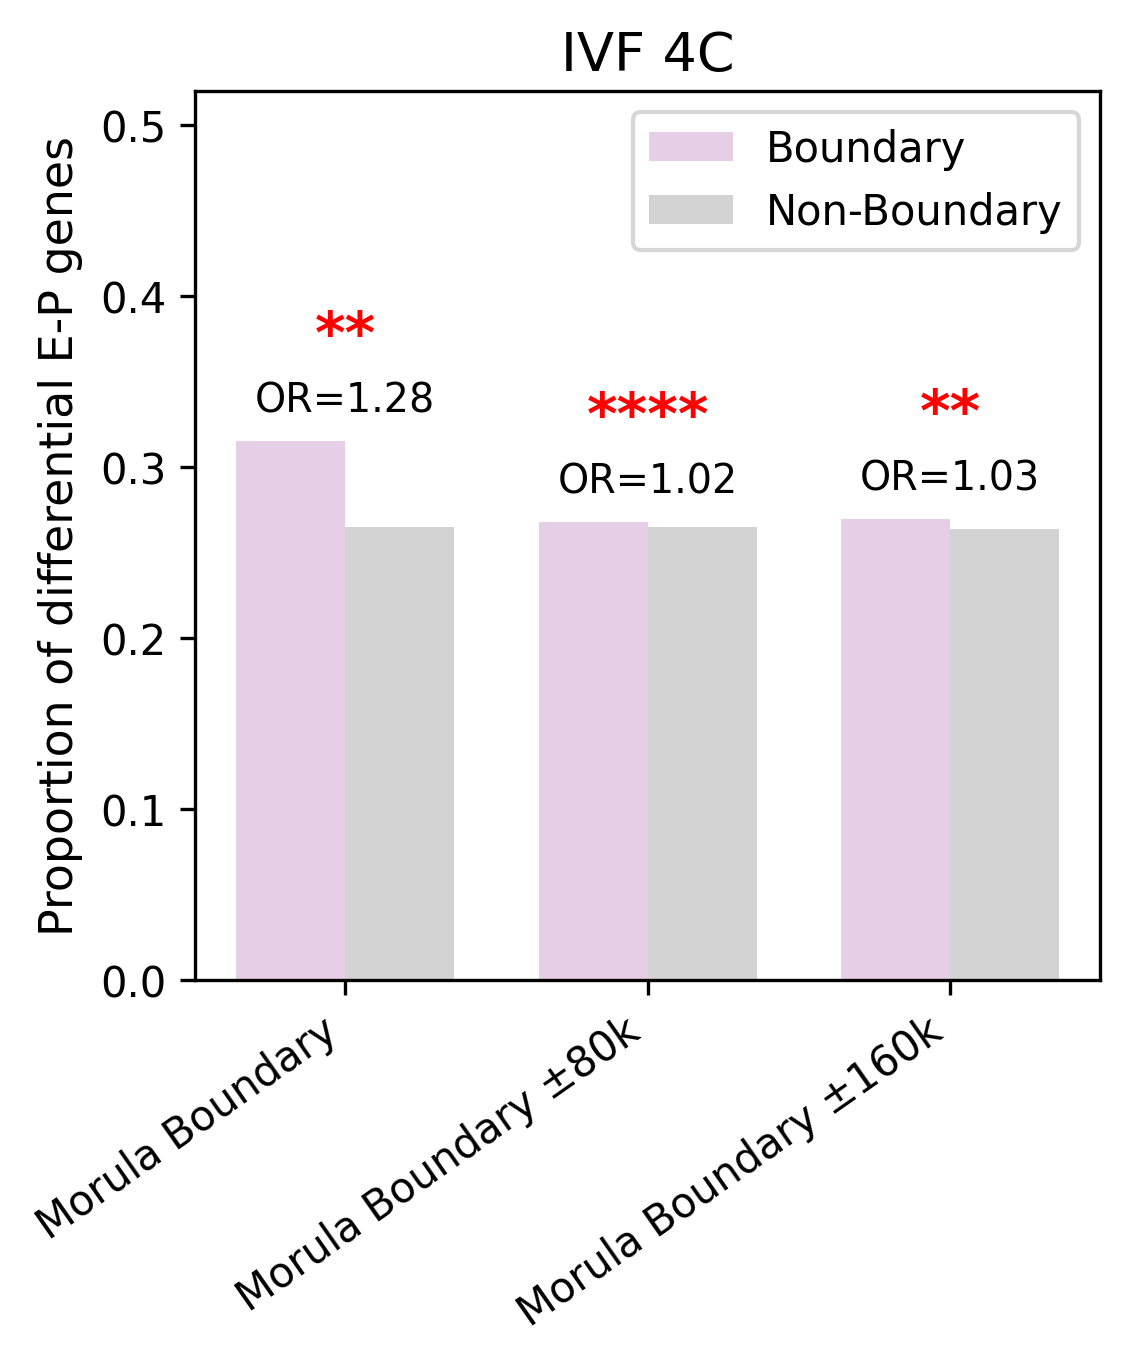

In [15]:
# IVF 4C morula 附近的差异边界
# EPI 在 boundary 富集情况

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union

# 全局绘图风格
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")

    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d


def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")

    conditions = [
        {
            "name": "IVF 4C",
            "diff_file": "IVF_4C_diff_EPgenes.H3K27ac.0.01.txt",
            "regions": [
                ("Morula Boundary",
                 "dedoc2_IVF_4C_debin_genes_id.new.txt",
                 "dedoc2_IVF_4C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k",
                 "dedoc2_IVF_4C_debin_flanking_80k_genes_id.new.txt",
                 "dedoc2_IVF_4C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k",
                 "dedoc2_IVF_4C_debin_flanking_160k_genes_id.new.txt",
                 "dedoc2_IVF_4C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # 绘图风格补充
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        print(f"\n=== {cond['name']} ===")
        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(diff_genes, target_genes, non_genes)

            # 打印 p 值和 OR
            print(f"{label}: p = {p:.4e}, OR = {odds:.3f}, 列联表 a={a}, b={b}, c={c}, d={d}")

            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width / 2, target_props, width, label="Boundary", color=colors["Boundary"])
        ax.bar(x + width / 2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of differential E-P genes", fontsize=11)

        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])

            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}',
                    ha='center', va='bottom', fontsize=9.5)

            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"

                ax.text(i, max_h + 0.045, stars,
                        ha='center', va='bottom', fontsize=14,
                        color='red', fontweight='bold')

        ax.legend()

    # 整体布局
    fig.suptitle("", fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)

    # 保存
    output_file = "IVF_4C_EPI_enrich_TADboundary_OR_stars.svg"
    plt.savefig(output_file, dpi=300, bbox_inches='tight', transparent=True)
    print(f"\n图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main()

yes
图片已保存：IVF_4C_ZGA_enrich_TADboundary_OR_stars.svg


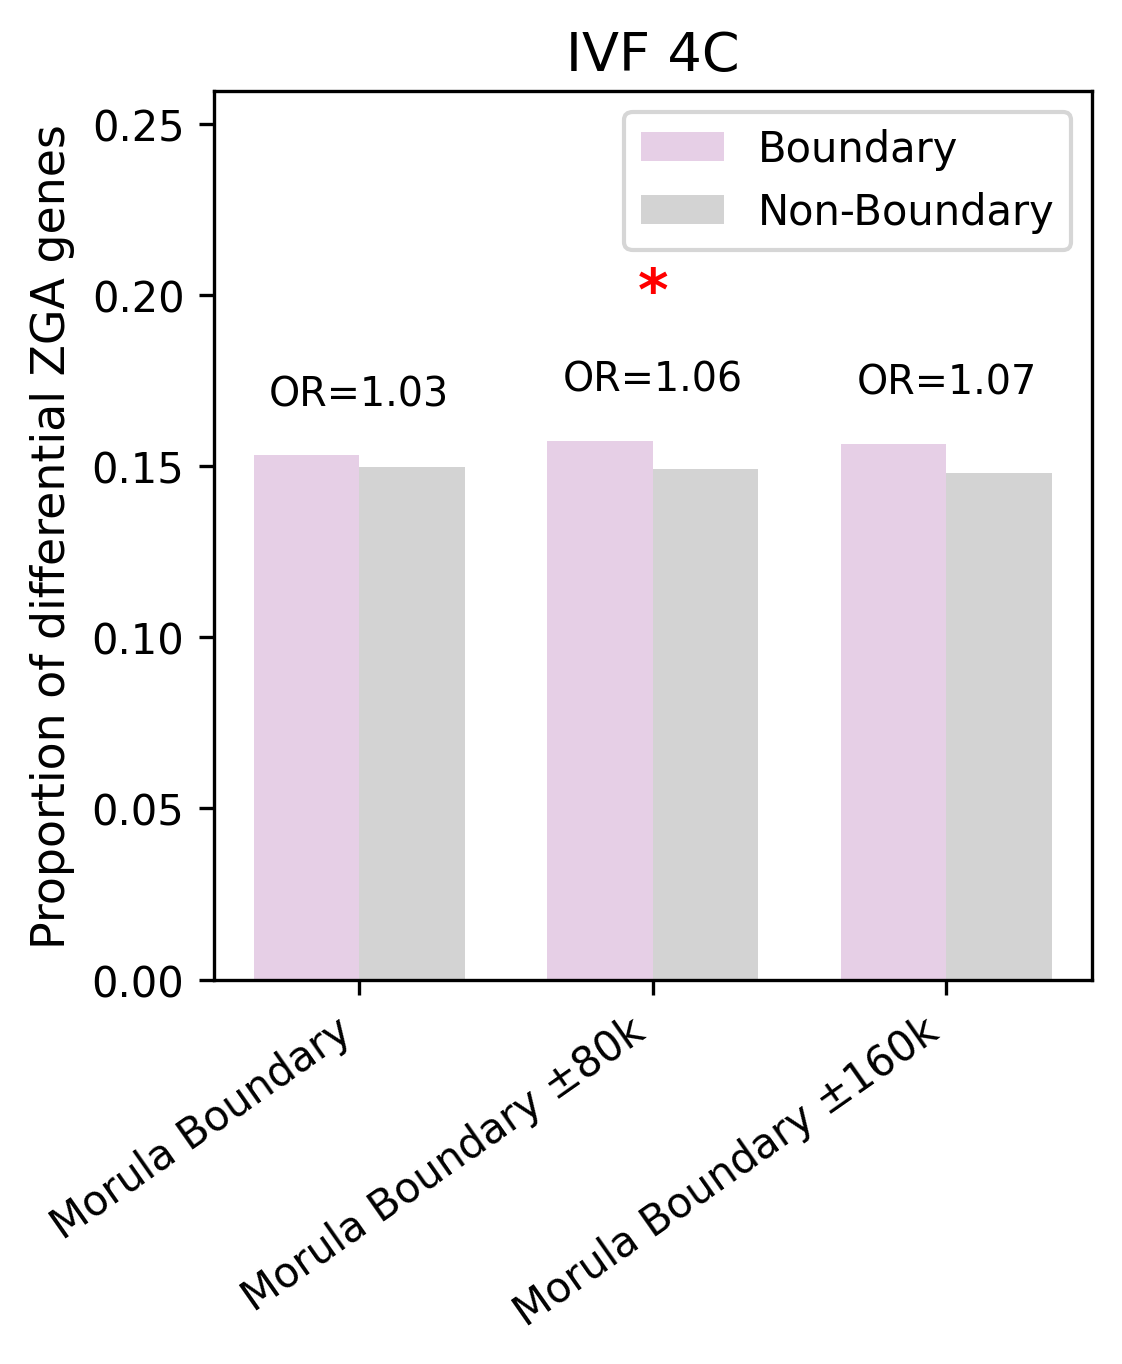

In [12]:
#IVF 4C morula 附近的差异边界
#EPI 在 boundary 富集情况
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union


def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")
    
    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d



def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")
    
    conditions = [
        {
            "name": "IVF 4C",
            "diff_file": "IVF_ZGAid.txt",
            "regions": [
                ("Morula Boundary", 
                 "dedoc2_IVF_4C_debin_genes_id.new.txt", 
                 "dedoc2_IVF_4C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k", 
                 "dedoc2_IVF_4C_debin_flanking_80k_genes_id.new.txt", 
                 "dedoc2_IVF_4C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k", 
                 "dedoc2_IVF_4C_debin_flanking_160k_genes_id.new.txt", 
                 "dedoc2_IVF_4C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # ── 绘图风格 ───────────────────────────────────────────────────
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes    = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(diff_genes, target_genes, non_genes)
            
            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non    = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width/2, target_props,   width, label="Boundary",     color=colors["Boundary"])
        ax.bar(x + width/2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of differential ZGA genes", fontsize=11)
        
        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])
            
            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}', 
                    ha='center', va='bottom', fontsize=9.5)
            
            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"
                print('yes')
                ax.text(i, max_h + 0.035, stars, 
                        ha='center', va='bottom', fontsize=14, 
                        color='red', fontweight='bold')

        # 图例放到右上角外部
        #ax.legend(frameon=True, fontsize=10, 
        #          loc='upper left', bbox_to_anchor=(1.02, 1.0))
        ax.legend()
    # 整体布局
    fig.suptitle("", 
                 fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)  # 给右侧图例留空间

    # 保存
    output_file = "IVF_4C_ZGA_enrich_TADboundary_OR_stars.svg"
    plt.savefig('IVF_4C_ZGA_enrich_TADboundary_OR_stars.svg', dpi=300, bbox_inches='tight', transparent=True)
    print(f"图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main() 

图片已保存：IVF_4C_diff_EPI_ZGA_overlap_enrich_TADboundary_OR_stars.svg


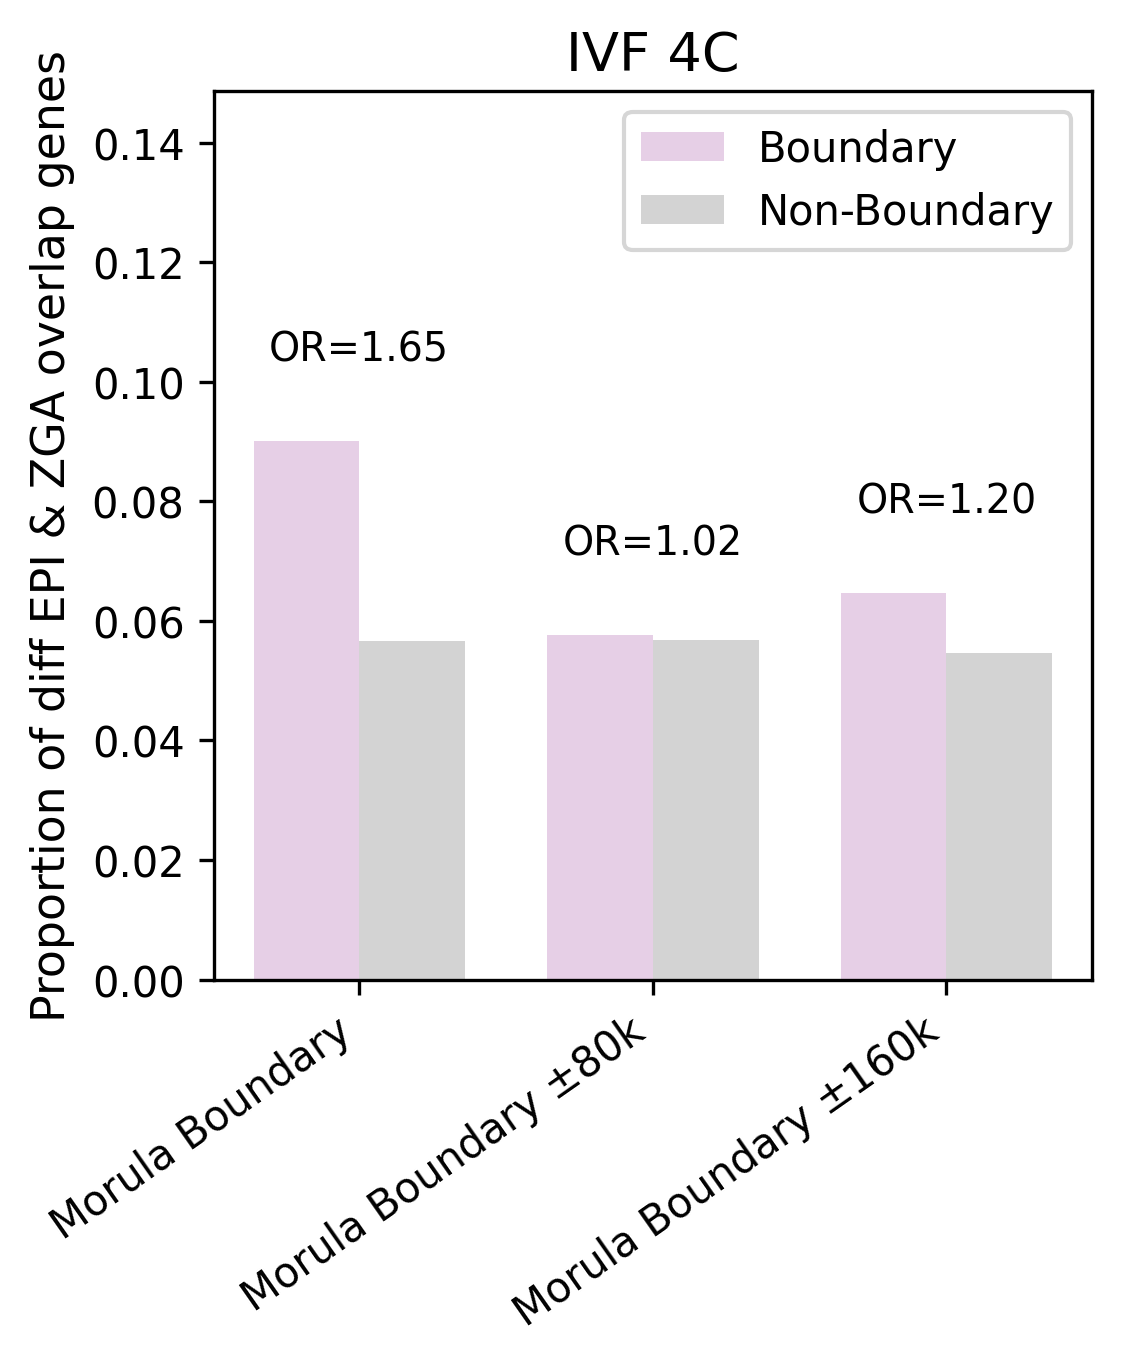

In [13]:
#IVF 4C morula 附近的差异边界
#EPI 在 boundary 富集情况
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union


def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")
    
    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d



def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")
    
    conditions = [
        {
            "name": "IVF 4C",
            "diff_file": "IVF_4C_diff_EPI_ZGA_overlap_id.txt",
            "regions": [
                ("Morula Boundary", 
                 "dedoc2_IVF_4C_debin_genes_id.new.txt", 
                 "dedoc2_IVF_4C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k", 
                 "dedoc2_IVF_4C_debin_flanking_80k_genes_id.new.txt", 
                 "dedoc2_IVF_4C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k", 
                 "dedoc2_IVF_4C_debin_flanking_160k_genes_id.new.txt", 
                 "dedoc2_IVF_4C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # ── 绘图风格 ───────────────────────────────────────────────────
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes    = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(diff_genes, target_genes, non_genes)
            
            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non    = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width/2, target_props,   width, label="Boundary",     color=colors["Boundary"])
        ax.bar(x + width/2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of diff EPI & ZGA overlap genes", fontsize=11)
        
        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])
            
            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}', 
                    ha='center', va='bottom', fontsize=9.5)
            
            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"
                print('yes')
                ax.text(i, max_h + 0.035, stars, 
                        ha='center', va='bottom', fontsize=14, 
                        color='red', fontweight='bold')

        # 图例放到右上角外部
        #ax.legend(frameon=True, fontsize=10, 
        #          loc='upper left', bbox_to_anchor=(1.02, 1.0))
        ax.legend()
    # 整体布局
    fig.suptitle("", 
                 fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)  # 给右侧图例留空间

    # 保存
    output_file = "IVF_4C_diff_EPI_ZGA_overlap_enrich_TADboundary_OR_stars.svg"
    plt.savefig('IVF_4C_diff_EPI_ZGA_overlap_enrich_TADboundary_OR_stars.svg', dpi=300, bbox_inches='tight', transparent=True)
    print(f"图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main() 

PA 2C | Morula Boundary | P-value = 5.680946e-01 | OR = 0.8889 | a=10, b=5729, c=31, d=15786
PA 2C | Morula Boundary ±80k | P-value = 1.014133e-17 | OR = 1.2641 | a=544, b=5195, c=1210, d=14607
PA 2C | Morula Boundary ±160k | P-value = 8.104998e-05 | OR = 0.9841 | a=463, b=5276, c=1295, d=14522
图片已保存：PA_2C_EPI_enrich_TADboundary_OR_stars.svg


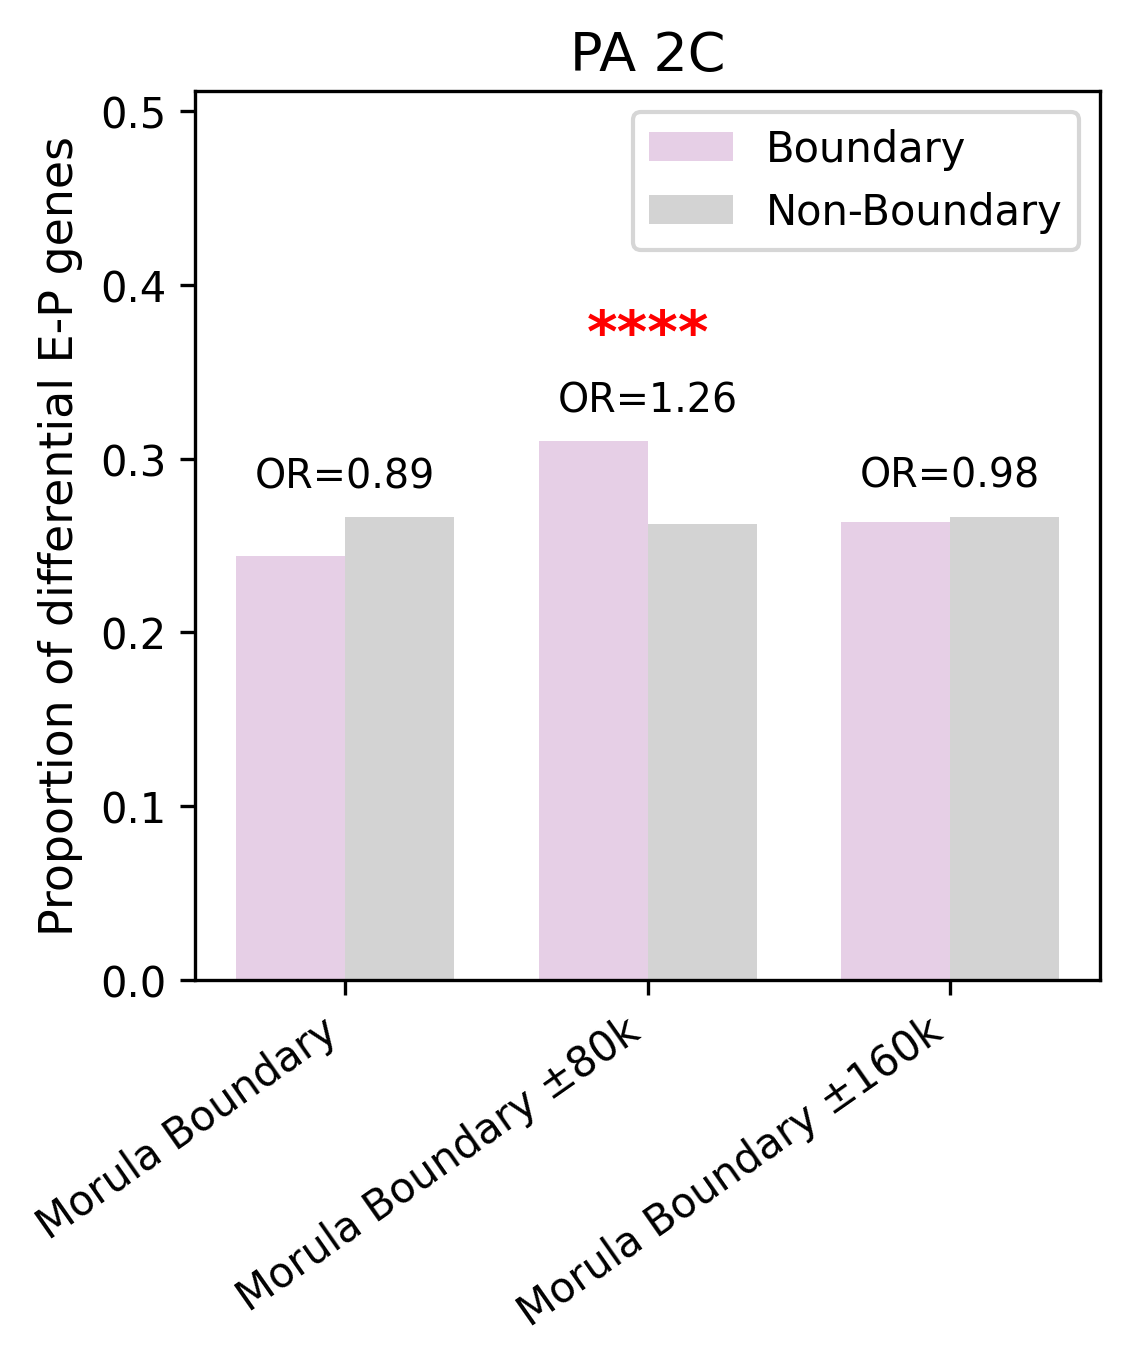

In [16]:
#PA 2C morula 附近的差异边界
#EPI 在 boundary 富集情况

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")
    
    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d



def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")
    
    conditions = [
        {
            "name": "PA 2C",
            "diff_file": "IVF_2C_diff_EPgenes.H3K27ac.0.01.txt",
            "regions": [
                ("Morula Boundary", 
                 "dedoc2_PA_2C_debin_genes_id.new.txt", 
                 "dedoc2_PA_2C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k", 
                 "dedoc2_PA_2C_debin_flanking_80k_genes_id.new.txt", 
                 "dedoc2_PA_2C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k", 
                 "dedoc2_PA_2C_debin_flanking_160k_genes_id.new.txt", 
                 "dedoc2_PA_2C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # ── 绘图风格 ───────────────────────────────────────────────────
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes    = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(
                diff_genes, target_genes, non_genes
            )
            
            print(
                f"{cond['name']} | {label} | "
                f"P-value = {p:.6e} | OR = {odds:.4f} | "
                f"a={a}, b={b}, c={c}, d={d}"
            )
            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non    = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width/2, target_props,   width, label="Boundary",     color=colors["Boundary"])
        ax.bar(x + width/2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of differential E-P genes", fontsize=11)
        
        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])
            
            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}', 
                    ha='center', va='bottom', fontsize=9.5)
            
            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"
                
                ax.text(i, max_h + 0.045, stars, 
                        ha='center', va='bottom', fontsize=14, 
                        color='red', fontweight='bold')

        # 图例放到右上角外部
        #ax.legend(frameon=True, fontsize=10, 
        #          loc='upper left', bbox_to_anchor=(1.02, 1.0))
        ax.legend()
    # 整体布局
    fig.suptitle("", 
                 fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)  # 给右侧图例留空间

    # 保存
    output_file = "PA_2C_EPI_enrich_TADboundary_OR_stars.svg"
    plt.savefig('PA_2C_EPI_enrich_TADboundary_OR_stars.svg', dpi=300, bbox_inches='tight', transparent=True)
    print(f"图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main() 

PA 4C | Morula Boundary | P-value = 1.164683e-03 | OR = 1.3591 | a=46, b=5983, c=94, d=16617
PA 4C | Morula Boundary ±80k | P-value = 1.330517e-13 | OR = 1.1557 | a=1064, b=4965, c=2614, d=14097
PA 4C | Morula Boundary ±160k | P-value = 5.108536e-11 | OR = 1.1932 | a=1554, b=4475, c=3767, d=12944
图片已保存：PA_4C_EPI_enrich_TADboundary_OR_stars.svg


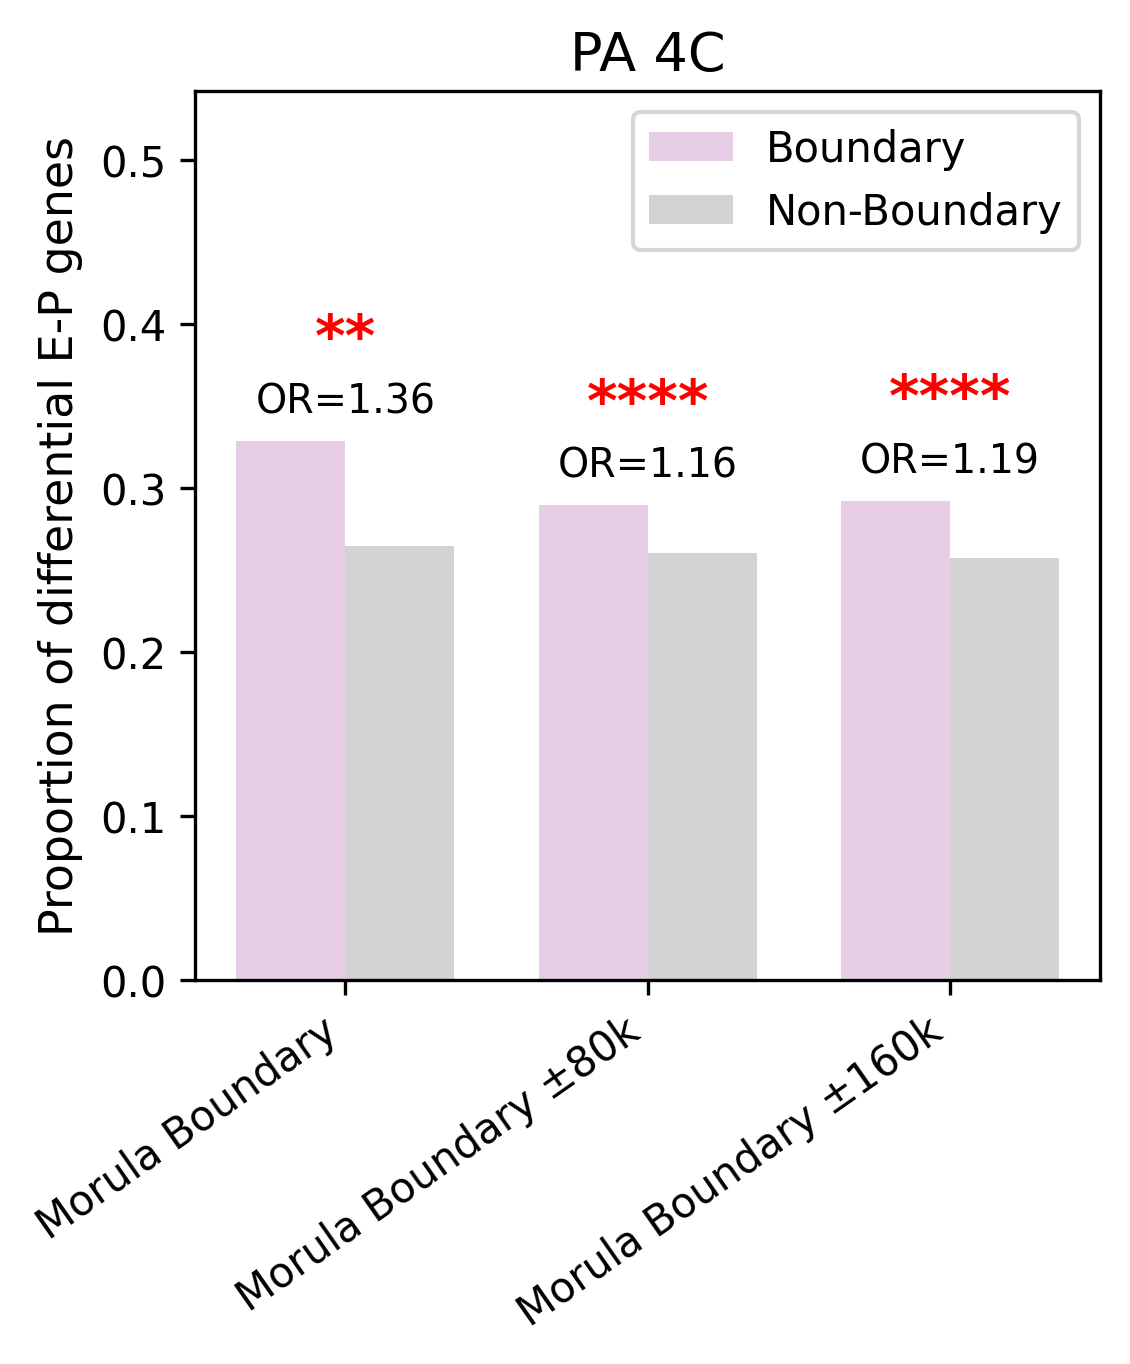

In [17]:
#PA 4C morula 附近的差异边界
#EPI 在 boundary 富集情况
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import fisher_exact
from pathlib import Path
from typing import List, Tuple, Union


def read_gene_list(file_path: Union[str, Path]) -> List[str]:
    """读取文件第一列的基因ID"""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"文件未找到: {path}")
    
    genes = []
    with path.open('r') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                gene_id = line.split('\t')[0].strip()
                if gene_id:
                    genes.append(gene_id)
    return genes


def fisher_enrichment(
    diff_genes: List[str],
    target_genes: List[str],
    non_target_genes: List[str]
) -> Tuple[float, float, int, int, int, int]:
    """Fisher精确检验 + 计算 OR"""
    a = len(set(diff_genes) & set(target_genes))           # diff ∩ target
    b = len(diff_genes) - a                                 # diff - target
    c = len(set(target_genes) - set(diff_genes))           # target - diff
    d = len(non_target_genes) - c                           # non - diff
    
    table = np.array([[a, b], [c, d]], dtype=float)
    xx, p_value = fisher_exact(table)
    
    diff_set = set(diff_genes)
    target_set = set(target_genes)
    non_target_set = set(non_target_genes)

    a = len(diff_set & target_set)
    b = len(diff_set & non_target_set)
    c = len(target_set - diff_set)
    d = len(non_target_set - diff_set)

    table = np.array([[a, b], [c, d]])
    odds_ratio, xx = fisher_exact(table)
    
    return p_value, odds_ratio, a, b, c, d



def overlap_proportion(diff_genes: List[str], gene_set: List[str]) -> float:
    """计算重叠比例"""
    if not gene_set:
        return 0.0
    overlap = len(set(diff_genes) & set(gene_set))
    return overlap / len(gene_set)


def main():
    # ── 配置部分 ───────────────────────────────────────────────────
    base_dir = Path("/home/lihaoxing/deDoc2-main/PA_40k_TAD_cat/2c_4c_subtad/boundary_frequency/morula_boundary_deboundary")
    
    conditions = [
        {
            "name": "PA 4C",
            "diff_file": "IVF_4C_diff_EPgenes.H3K27ac.0.01.txt",
            "regions": [
                ("Morula Boundary", 
                 "dedoc2_PA_4C_debin_genes_id.new.txt", 
                 "dedoc2_PA_4C_debin_genes_id.non.txt"),
                ("Morula Boundary ±80k", 
                 "dedoc2_PA_4C_debin_flanking_80k_genes_id.new.txt", 
                 "dedoc2_PA_4C_debin_flanking_80k_genes_id.non.txt"),
                ("Morula Boundary ±160k", 
                 "dedoc2_PA_4C_debin_flanking_160k_genes_id.new.txt", 
                 "dedoc2_PA_4C_debin_flanking_160k_genes_id.non.txt"),
            ]
        },
        # 如果以后要加其他条件（如4C），在这里继续添加即可
    ]

    # ── 绘图风格 ───────────────────────────────────────────────────
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'svg.fonttype': 'none',
        'figure.dpi': 300,
    })

    fig, axes = plt.subplots(1, len(conditions), figsize=(4.5 * len(conditions), 4.8), sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    colors = {
        "Boundary": "#e6cfe6",
        "Non-Boundary": "lightgrey"
    }

    # ── 主循环 ─────────────────────────────────────────────────────
    for ax, cond in zip(axes, conditions):
        diff_genes = read_gene_list(base_dir / cond["diff_file"])

        labels = []
        target_props = []
        non_target_props = []
        pvals = []
        odds_list = []

        for label, target_file, non_file in cond["regions"]:
            target_genes = read_gene_list(base_dir / target_file)
            non_genes    = read_gene_list(base_dir / non_file)

            p, odds, a, b, c, d = fisher_enrichment(
                diff_genes, target_genes, non_genes
            )
            
            print(
                f"{cond['name']} | {label} | "
                f"P-value = {p:.6e} | OR = {odds:.4f} | "
                f"a={a}, b={b}, c={c}, d={d}"
            )
            
            prop_target = overlap_proportion(diff_genes, target_genes)
            prop_non    = overlap_proportion(diff_genes, non_genes)

            labels.append(label)
            target_props.append(prop_target)
            non_target_props.append(prop_non)
            pvals.append(p)
            odds_list.append(odds)

        # ── 柱状图 ──────────────────────────────────────────────────
        x = np.arange(len(labels))
        width = 0.36

        ax.bar(x - width/2, target_props,   width, label="Boundary",     color=colors["Boundary"])
        ax.bar(x + width/2, non_target_props, width, label="Non-Boundary", color=colors["Non-Boundary"])

        ax.set_title(cond["name"], fontsize=13, pad=5)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)
        ax.set_ylabel("Proportion of differential E-P genes", fontsize=11)
        
        # y轴范围抬高，避免文字重叠
        max_prop = max(max(target_props + non_target_props), 0.01)
        ax.set_ylim(0, max_prop * 1.65)

        # ── 标注 OR + 星号 ──────────────────────────────────────────
        for i, (p, odds) in enumerate(zip(pvals, odds_list)):
            max_h = max(target_props[i], non_target_props[i])
            
            # 显示 OR 值
            ax.text(i, max_h + 0.012, f'OR={odds:.2f}', 
                    ha='center', va='bottom', fontsize=9.5)
            
            # 显著性星号（只在 boundary > non-boundary 且 p≤0.05 时显示）
            if target_props[i] > non_target_props[i] and p <= 0.05:
                if p <= 1e-4:
                    stars = "****"
                elif p <= 1e-3:
                    stars = "***"
                elif p <= 1e-2:
                    stars = "**"
                else:
                    stars = "*"
                
                ax.text(i, max_h + 0.045, stars, 
                        ha='center', va='bottom', fontsize=14, 
                        color='red', fontweight='bold')

        # 图例放到右上角外部
        #ax.legend(frameon=True, fontsize=10, 
        #          loc='upper left', bbox_to_anchor=(1.02, 1.0))
        ax.legend()
    # 整体布局
    fig.suptitle("", 
                 fontsize=14, y=1)
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.28, right=0.82)  # 给右侧图例留空间

    # 保存
    output_file = "PA_4C_EPI_enrich_TADboundary_OR_stars.svg"
    plt.savefig('PA_4C_EPI_enrich_TADboundary_OR_stars.svg', dpi=300, bbox_inches='tight', transparent=True)
    print(f"图片已保存：{output_file}")

    plt.show()  # 非交互环境可注释掉


if __name__ == "__main__":
    main() 